# Day 1 · Foundations of ML & Math Essentials
Load the crop yield vs rainfall data, split 80/20 in pure NumPy, compute mean / variance / std by hand.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
df = pd.read_csv("crop_yield.csv")          # put crop_yield.csv next to this notebook
print(df.shape)
df.head()

(1000000, 10)


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
0,West,Sandy,Cotton,897.077239,27.676966,False,True,Cloudy,122,6.555816
1,South,Clay,Rice,992.673282,18.026142,True,True,Rainy,140,8.527341
2,North,Loam,Barley,147.998025,29.794042,False,False,Sunny,106,1.127443
3,North,Sandy,Soybean,986.866331,16.644190,False,True,Rainy,146,6.517573
4,South,Silt,Wheat,730.379174,31.620687,True,True,Cloudy,110,7.248251


In [2]:
rain = df["Rainfall_mm"].to_numpy()
yld  = df["Yield_tons_per_hectare"].to_numpy()

# 80/20 split: shuffle indices with a seeded RNG, then slice
rng = np.random.default_rng(42)
idx = rng.permutation(len(df))
cut = int(0.8 * len(df))
train_idx, test_idx = idx[:cut], idx[cut:]
X_train, X_test = rain[train_idx], rain[test_idx]
y_train, y_test = yld[train_idx],  yld[test_idx]
print("train:", X_train.shape, " test:", X_test.shape, " (no overlap:", np.intersect1d(train_idx, test_idx).size == 0, ")")

train: (800000,)  test: (200000,)  (no overlap: True )


In [3]:
# Statistics computed from the definitions, not np.mean / np.var
def mean(a):     return a.sum() / a.size
def variance(a): return ((a - mean(a))**2).sum() / a.size      # population variance (ddof=0)
def std(a):      return variance(a) ** 0.5

rows = []
for name, arr in [("Rainfall train", X_train), ("Rainfall test", X_test),
                  ("Yield train", y_train),    ("Yield test", y_test)]:
    rows.append((name, mean(arr), variance(arr), std(arr)))
stats = pd.DataFrame(rows, columns=["set", "mean", "variance", "std"]).set_index("set")
stats

,mean,variance,std
set,,,
Rainfall train,549.969334,67496.371951,259.800639
Rainfall test,550.032169,67627.714674,260.053292
Yield train,4.649503,2.877754,1.696394
Yield test,4.649351,2.880760,1.697280


manual stats match NumPy


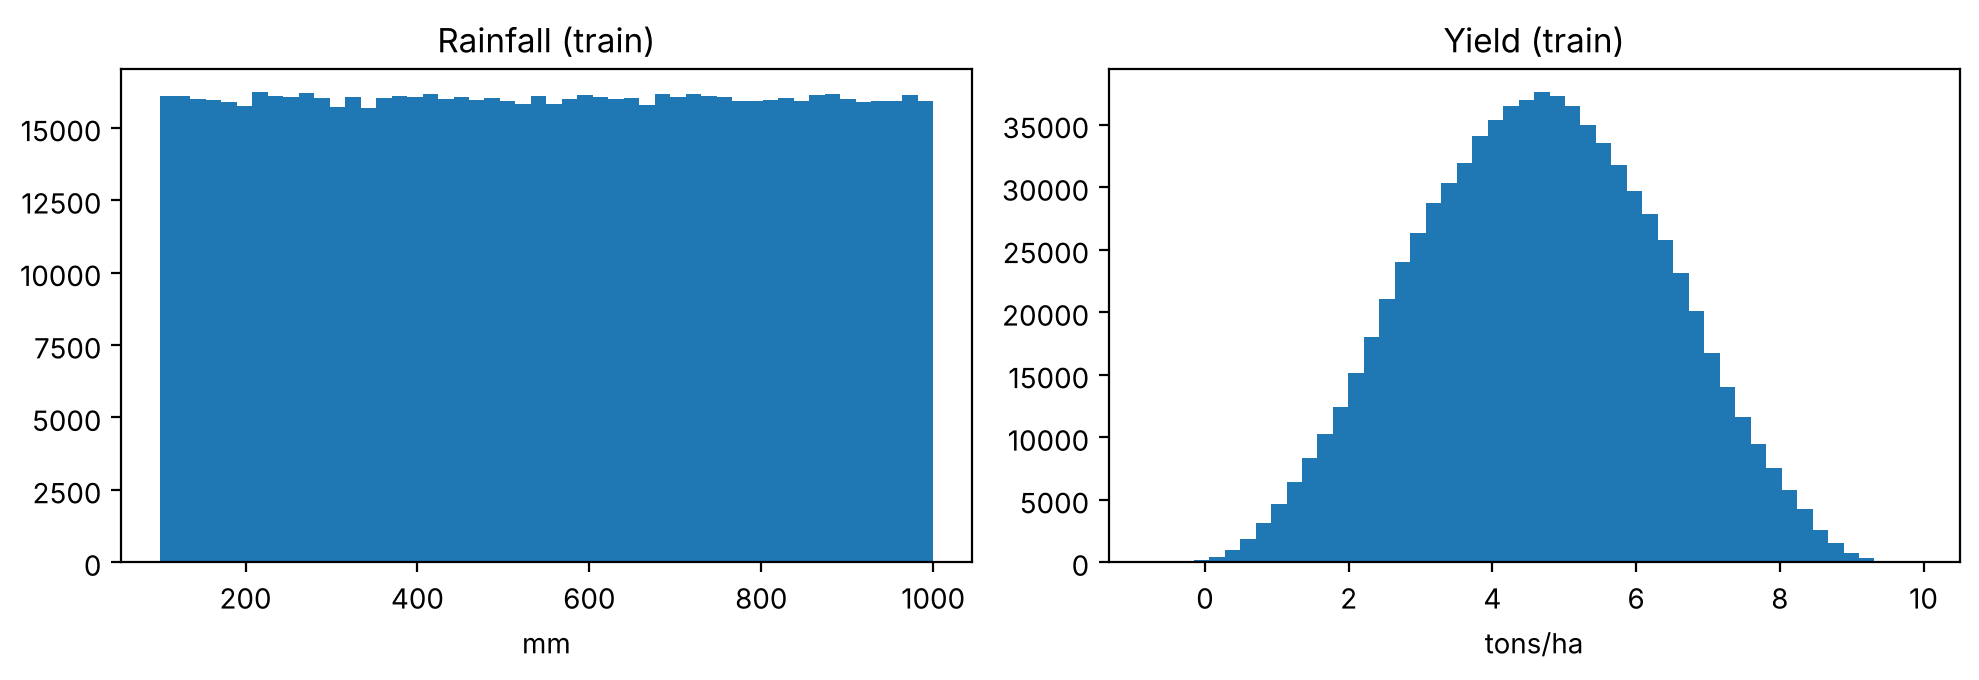

In [4]:
# Sanity check against NumPy
for arr in (X_train, X_test, y_train, y_test):
    assert np.isclose(mean(arr), arr.mean()) and np.isclose(variance(arr), arr.var()) and np.isclose(std(arr), arr.std())
print("manual stats match NumPy")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(X_train, bins=50); ax[0].set_title("Rainfall (train)"); ax[0].set_xlabel("mm")
ax[1].hist(y_train, bins=50); ax[1].set_title("Yield (train)");    ax[1].set_xlabel("tons/ha")
plt.tight_layout(); plt.show()